In [36]:


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.pyplot import MultipleLocator
import sys
import seaborn as sns
import warnings
import math
warnings.filterwarnings("ignore")
plt.rcParams['font.sans-serif'] = ['SimHei']  # 用来正常显示中文标签
plt.rcParams['axes.unicode_minus'] = False  # 用来正常显示负号
pd.set_option('display.max_rows', 100,'display.max_columns', 1000,"display.max_colwidth",1000,'display.width',1000)

from sklearn.metrics import *
from sklearn.linear_model import *
from sklearn.neighbors import *
from sklearn.svm import *
from sklearn.neural_network import *
from sklearn.tree import *
from sklearn.ensemble import *
from xgboost import *
import lightgbm as lgb
import tensorflow as tf
from tensorflow.keras import layers
from sklearn.preprocessing import *
from sklearn.ensemble import RandomForestRegressor as RFR
from sklearn.model_selection import *
data = pd.read_excel(r"C:\Users\wang\Downloads\深度学习房价预测\universal_algorithm\work_order\二手房数据（处理后）.xlsx", na_values=np.nan)
# 将“无抵押”替换为0
# 对所有分类数据进行独热编码
data = pd.get_dummies(data)


# 将数据划分输入和结果集
X = data[ data.columns[1:] ]
y_reg = data[ data.columns[0] ]

# 切分训练集和测试集， random_state是切分数据集的随机种子，要想复现本文的结果，随机种子应该一致
x_train, x_test, y_train, y_test = train_test_split(X, y_reg, test_size=0.3, random_state=42)
# 评价指标函数定义，其中R2的指标可以由模型自身得出，后面的score即为R2
def evaluation(model):
    ypred = model.predict(x_test)
    mae = mean_absolute_error(y_test, ypred)
    mse = mean_squared_error(y_test, ypred)
    rmse = math.sqrt(mse)
    r2 = r2_score(y_test, ypred)
    print("MAE: %.2f" % mae)
    print("MSE: %.2f" % mse)
    print("RMSE: %.2f" % rmse)
    print("R^2: %.2f" % r2)
    return ypred


model_LR = LinearRegression()
model_LR.fit(x_train, y_train)
print("params: ", model_LR.get_params())
print("train score: ", model_LR.score(x_train, y_train))
print("test score: ", model_LR.score(x_test, y_test))
predict_y = evaluation(model_LR)


params:  {'copy_X': True, 'fit_intercept': True, 'n_jobs': None, 'positive': False}
train score:  0.9556283028262542
test score:  0.9398107695905197
MAE: 11.55
MSE: 353.81
RMSE: 18.81
R^2: 0.94


In [3]:
test_y = np.array(y_test)


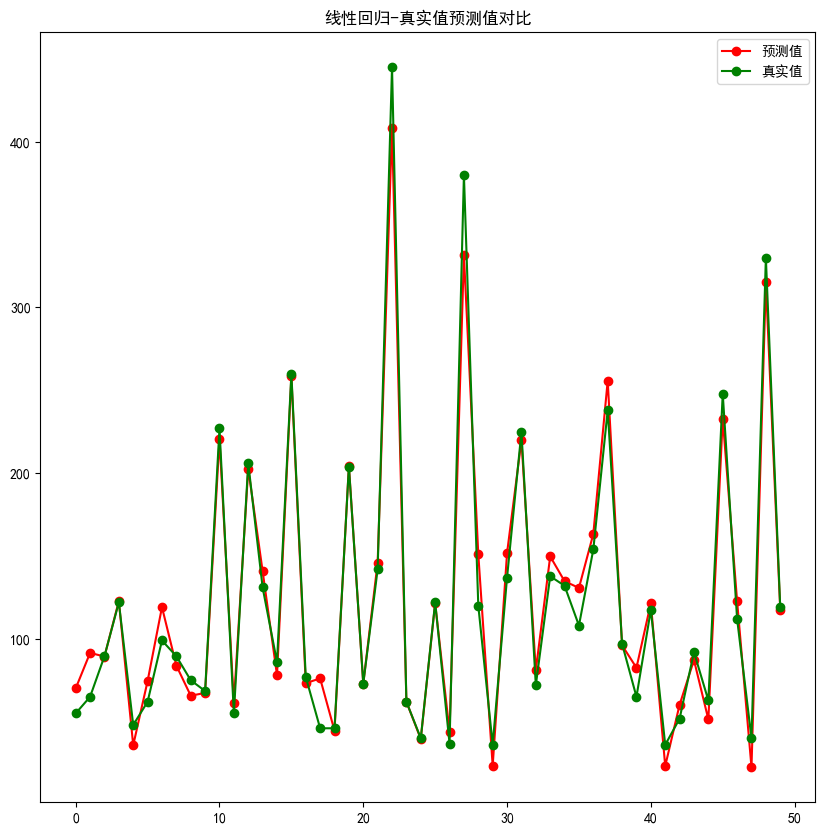

In [37]:
plt.figure(figsize=(10,10))
plt.title('线性回归-真实值预测值对比')
plt.plot(predict_y[:50], 'ro-', label='预测值')
plt.plot(test_y[:50], 'go-', label='真实值')
plt.legend()
plt.show()


In [39]:
model_knn = KNeighborsRegressor()
model_knn.fit(x_train, y_train)
print("params: ", model_knn.get_params())
print("train score: ", model_knn.score(x_train, y_train))
print("test score: ", model_knn.score(x_test, y_test))
predict_y = evaluation(model_knn)


params:  {'algorithm': 'auto', 'leaf_size': 30, 'metric': 'minkowski', 'metric_params': None, 'n_jobs': None, 'n_neighbors': 5, 'p': 2, 'weights': 'uniform'}
train score:  0.8055745690649098
test score:  0.7144393809856229
MAE: 27.67
MSE: 1678.59
RMSE: 40.97
R^2: 0.71


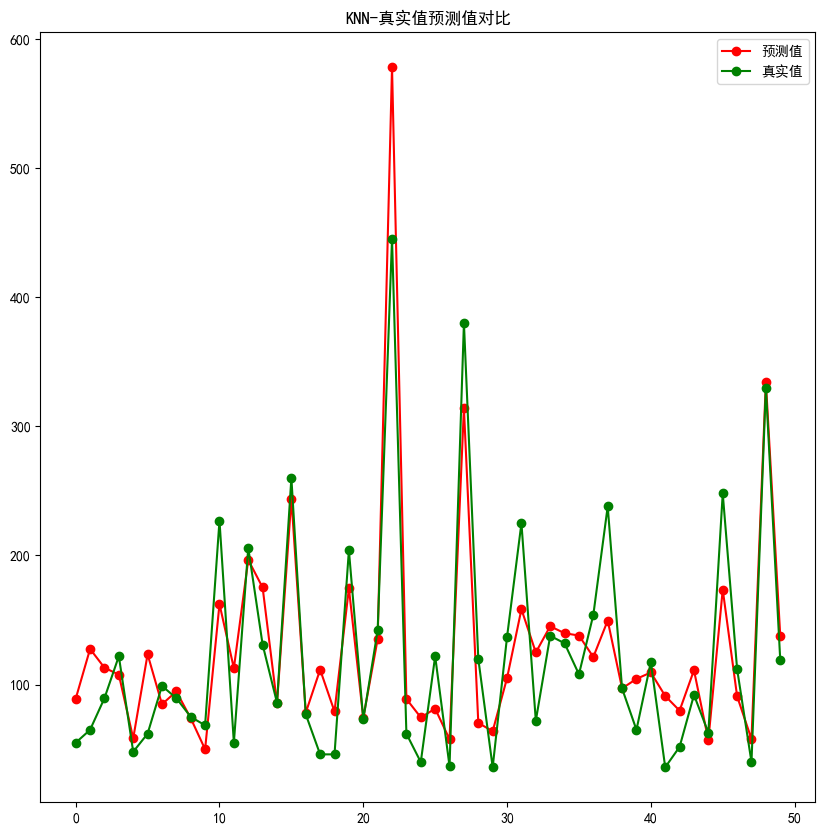

In [6]:
plt.figure(figsize=(10,10))
plt.title('KNN-真实值预测值对比')
plt.plot(predict_y[:50], 'ro-', label='预测值')
plt.plot(test_y[:50], 'go-', label='真实值')
plt.legend()
plt.show()


In [40]:
model_dtr = DecisionTreeRegressor(max_depth = 5, random_state=30)
model_dtr.fit(x_train, y_train)
print("params: ", model_dtr.get_params())
print("train score: ", model_dtr.score(x_train, y_train))
print("test score: ", model_dtr.score(x_test, y_test))
predict_y = evaluation(model_dtr)
# 决策树

params:  {'ccp_alpha': 0.0, 'criterion': 'squared_error', 'max_depth': 5, 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'random_state': 30, 'splitter': 'best'}
train score:  0.9624891829996234
test score:  0.9457849042838975
MAE: 12.19
MSE: 318.69
RMSE: 17.85
R^2: 0.95


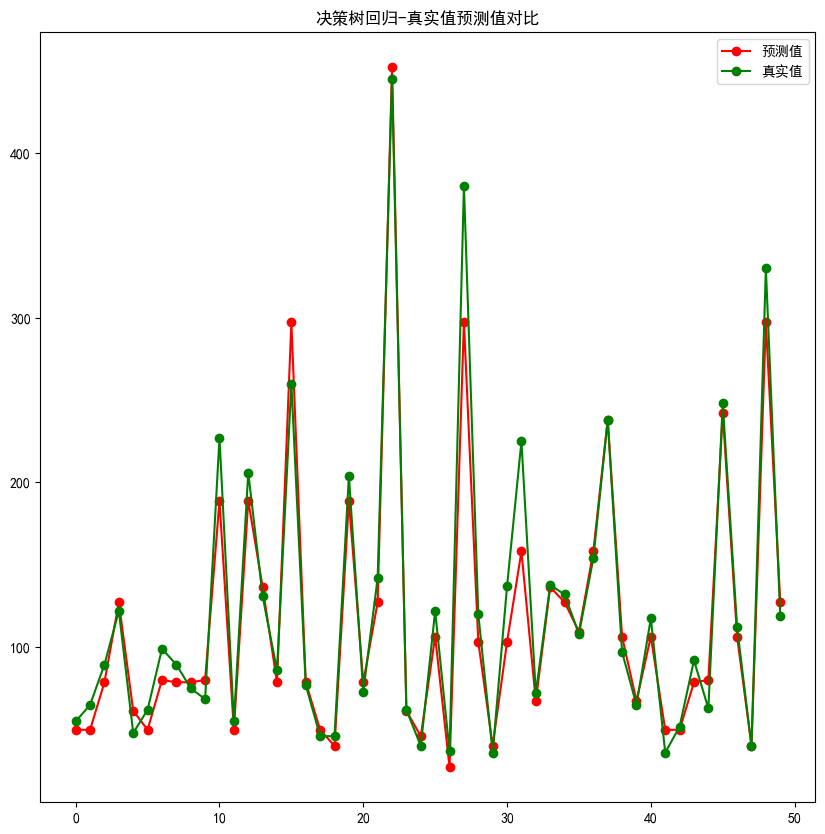

In [8]:
plt.figure(figsize=(10,10))
plt.title('决策树回归-真实值预测值对比')
plt.plot(predict_y[:50], 'ro-', label='预测值')
plt.plot(test_y[:50], 'go-', label='真实值')
plt.legend()
plt.show()


In [44]:
model_rfr = RandomForestRegressor(random_state=30)
model_rfr.fit(x_train, y_train)
print("params: ", model_rfr.get_params())
print("train score: ", model_rfr.score(x_train, y_train))
print("test score: ", model_rfr.score(x_test, y_test))
predict_y = evaluation(model_rfr)


params:  {'bootstrap': True, 'ccp_alpha': 0.0, 'criterion': 'squared_error', 'max_depth': None, 'max_features': 1.0, 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 100, 'n_jobs': None, 'oob_score': False, 'random_state': 30, 'verbose': 0, 'warm_start': False}
train score:  0.9968918233476924
test score:  0.9908333581352554
MAE: 2.52
MSE: 53.88
RMSE: 7.34
R^2: 0.99


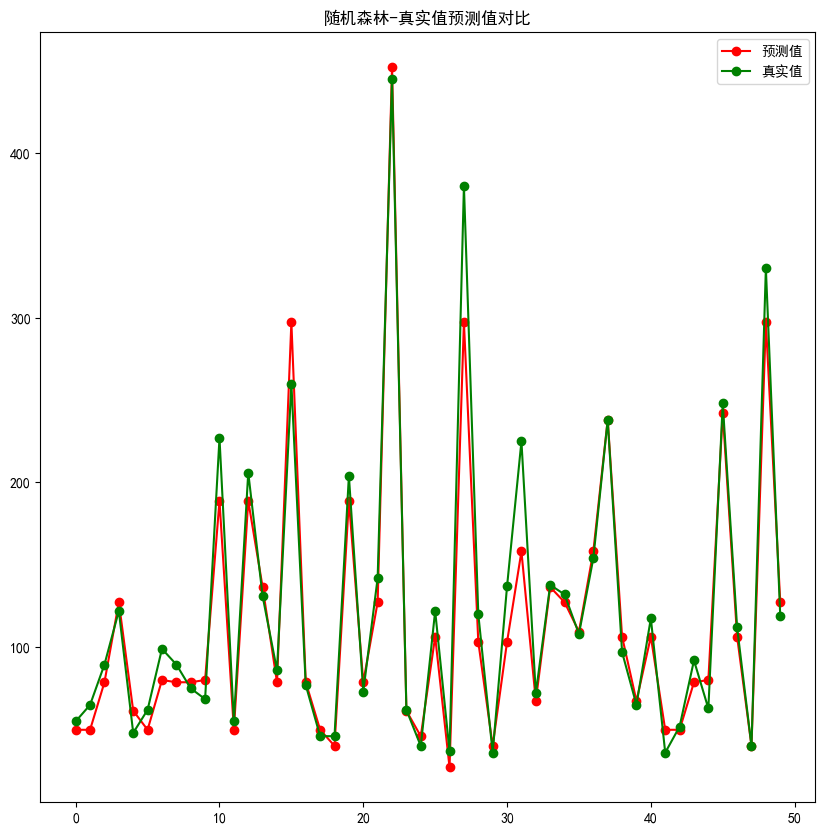

In [41]:
plt.figure(figsize=(10,10))
plt.title('随机森林-真实值预测值对比')
plt.plot(predict_y[:50], 'ro-', label='预测值')
plt.plot(test_y[:50], 'go-', label='真实值')
plt.legend()
plt.show()


In [42]:
model_xgbr = XGBRegressor(n_estimators = 200, max_depth=5, random_state=1024)
model_xgbr.fit(x_train, y_train)
print("params: ", model_xgbr.get_params())
print("train score: ", model_xgbr.score(x_train, y_train))
print("test score: ", model_xgbr.score(x_test, y_test))
predict_y = evaluation(model_xgbr)


params:  {'objective': 'reg:squarederror', 'base_score': None, 'booster': None, 'callbacks': None, 'colsample_bylevel': None, 'colsample_bynode': None, 'colsample_bytree': None, 'device': None, 'early_stopping_rounds': None, 'enable_categorical': False, 'eval_metric': None, 'feature_types': None, 'gamma': None, 'grow_policy': None, 'importance_type': None, 'interaction_constraints': None, 'learning_rate': None, 'max_bin': None, 'max_cat_threshold': None, 'max_cat_to_onehot': None, 'max_delta_step': None, 'max_depth': 5, 'max_leaves': None, 'min_child_weight': None, 'missing': nan, 'monotone_constraints': None, 'multi_strategy': None, 'n_estimators': 200, 'n_jobs': None, 'num_parallel_tree': None, 'random_state': 1024, 'reg_alpha': None, 'reg_lambda': None, 'sampling_method': None, 'scale_pos_weight': None, 'subsample': None, 'tree_method': None, 'validate_parameters': None, 'verbosity': None}
train score:  0.9997748132281744
test score:  0.9852408933615769
MAE: 3.38
MSE: 86.76
RMSE: 9.

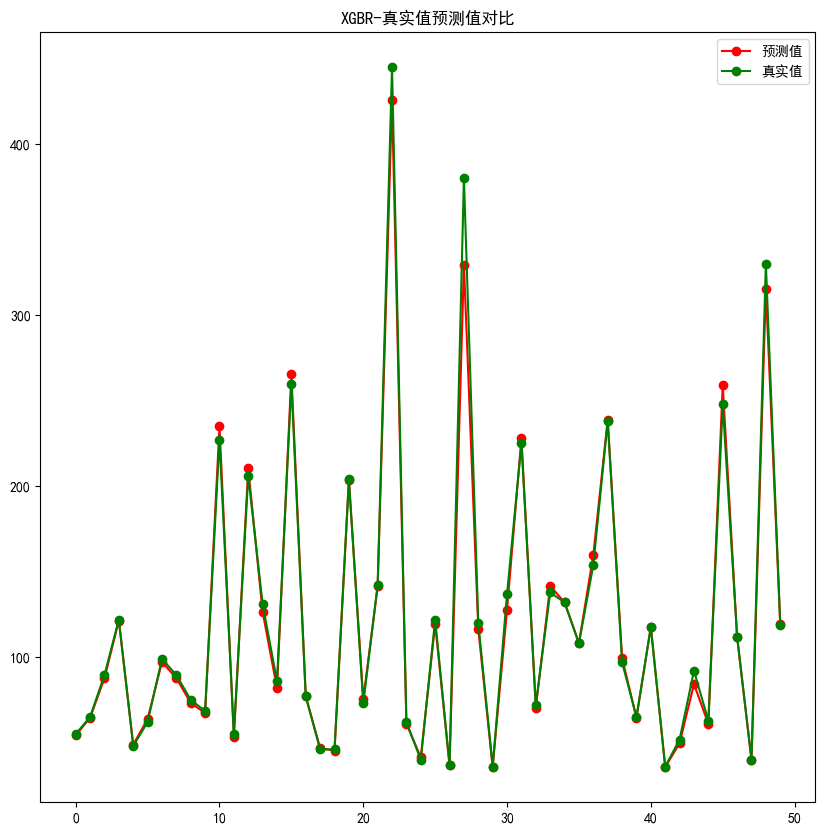

In [12]:
plt.figure(figsize=(10,10))
plt.title('XGBR-真实值预测值对比')
plt.plot(predict_y[:50], 'ro-', label='预测值')
plt.plot(test_y[:50], 'go-', label='真实值')
plt.legend()
plt.show()


In [43]:
model_voting = VotingRegressor(estimators=[('model_LR', model_LR),
                                           ('model_knn', model_knn), 
                                           ('model_dtr', model_dtr),
                                           ('model_rfr', model_rfr),
                                           ('model_xgbr', model_xgbr)])
model_voting.fit(x_train, y_train)
# print("params: ", model_voting.get_params())
print("train score: ", model_voting.score(x_train, y_train))
print("test score: ", model_voting.score(x_test, y_test))
predict_y = evaluation(model_voting)


train score:  0.9840993156546499
test score:  0.9714026257162937
MAE: 7.33
MSE: 168.10
RMSE: 12.97
R^2: 0.97


In [14]:
test_y = np.array(y_test)


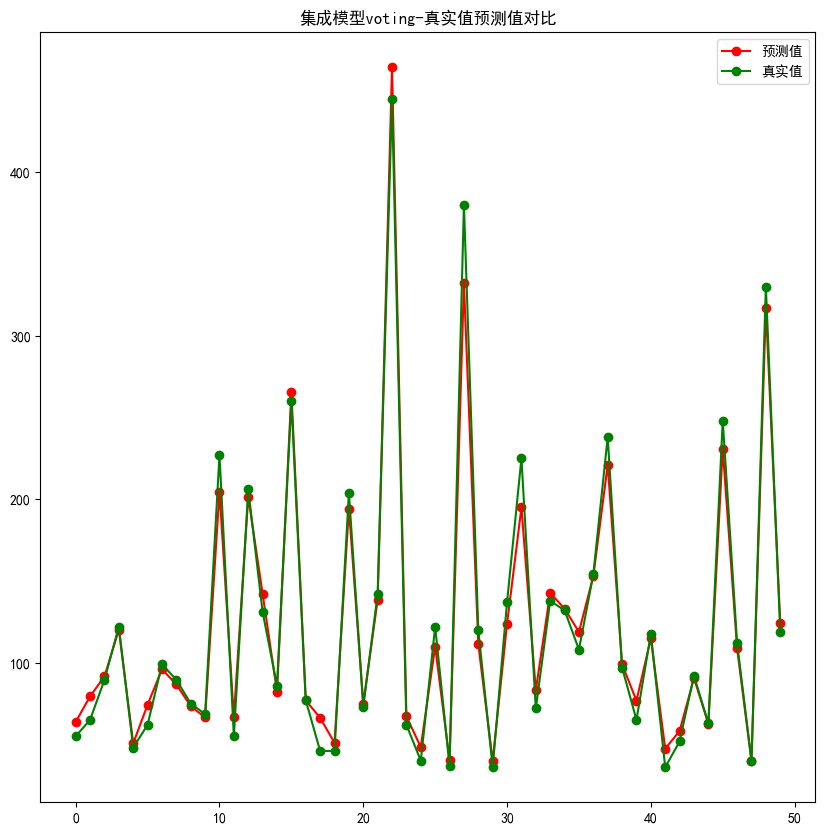

In [16]:
plt.figure(figsize=(10,10))
plt.title('集成模型voting-真实值预测值对比')
plt.plot(predict_y[:50], 'ro-', label='预测值')
plt.plot(test_y[:50], 'go-', label='真实值')
plt.legend()
plt.show()



In [20]:
# 1、模型初始化
model_tf = tf.keras.Sequential()

# 2、添加隐藏层，并设置激活函数，这里我们用relu
model_tf.add(layers.Dense(128, activation='relu'))
model_tf.add(layers.Dense(64, activation='relu'))
model_tf.add(layers.Dense(8, activation='relu'))
model_tf.add(layers.Dense(4, activation='relu'))
model_tf.add(layers.Dense(1, activation='relu'))

# 3、初始化输入的shape，86为输入的特征数量
model_tf.build(input_shape =(None, 762))


# 4、编译模型
model_tf.compile(optimizer=tf.keras.optimizers.RMSprop(0.001),
             loss=tf.keras.losses.mean_squared_error,
             metrics=['mse', 'mae'])

# 5、模型训练
history = model_tf.fit(train_x, train_y, epochs=200, batch_size=128,
                    validation_split = 0.2, #从测试集中划分80%给训练集
                    validation_freq = 1) #测试的间隔次数为1

# 获取模型训练过程
model_tf.summary()


Epoch 1/200
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 16625.0527 - mae: 103.2644 - mse: 16625.0527 - val_loss: 13243.5811 - val_mae: 91.4365 - val_mse: 13243.5811
Epoch 2/200
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 11840.1494 - mae: 82.5748 - mse: 11840.1494 - val_loss: 8194.0596 - val_mae: 65.7146 - val_mse: 8194.0596
Epoch 3/200
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 4681.9717 - mae: 47.6166 - mse: 4681.9717 - val_loss: 4969.2241 - val_mae: 42.0332 - val_mse: 4969.2241
Epoch 4/200
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 1949.7810 - mae: 24.7746 - mse: 1949.7810 - val_loss: 3823.8193 - val_mae: 34.7566 - val_mse: 3823.8193
Epoch 5/200
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1359.5125 - mae: 20.7801 - mse: 1359.5125 - val_loss: 3499.1289 - val_mae: 32.2732 - val_mse: 3499.1289
Epoch 6/200
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1042.2388 - mae: 17.7968 - mse: 1042.2388 - val_loss: 3081.6235 - val_mae: 29.8388 - val_mse: 3081.6235
Epoch 7/200
14

14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 20.4713 - mae: 3.2132 - mse: 20.4713 - val_loss: 9632.6982 - val_mae: 46.0742 - val_mse: 9632.6982
Epoch 86/200
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 35.3692 - mae: 3.9645 - mse: 35.3692 - val_loss: 10413.5156 - val_mae: 46.6019 - val_mse: 10413.5156
Epoch 87/200
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 27.3560 - mae: 3.6581 - mse: 27.3560 - val_loss: 9422.8916 - val_mae: 44.4895 - val_mse: 9422.8916
Epoch 88/200
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 27.2296 - mae: 3.7005 - mse: 27.2296 - val_loss: 9387.8467 - val_mae: 44.1199 - val_mse: 9387.8467
Epoch 89/200
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 34.8764 - mae: 4.0224 - mse: 34.8764 - val_loss: 9885.9287 - val_mae: 45.3292 - val_mse: 9885.9287
Epoch 90/200
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 27.8972 - mae: 3.7030 - mse: 27.8972 - val_loss: 10638.0957 - val_mae: 46.9588 - val_mse: 10638.0957
Epoch 91/200
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - l

14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 36.8922 - mae: 4.2212 - mse: 36.8922 - val_loss: 12184.1699 - val_mae: 51.4939 - val_mse: 12184.1699
Epoch 128/200
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 46.4277 - mae: 4.5083 - mse: 46.4277 - val_loss: 10203.9824 - val_mae: 46.8034 - val_mse: 10203.9824
Epoch 129/200
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 26.7050 - mae: 3.5480 - mse: 26.7050 - val_loss: 12181.8174 - val_mae: 49.8470 - val_mse: 12181.8174
Epoch 130/200
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 25.3035 - mae: 3.6267 - mse: 25.3035 - val_loss: 12028.5889 - val_mae: 49.5036 - val_mse: 12028.5889
Epoch 131/200
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 23.2633 - mae: 3.2291 - mse: 23.2633 - val_loss: 11757.1709 - val_mae: 49.6564 - val_mse: 11757.1709
Epoch 132/200
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 29.1671 - mae: 3.7249 - mse: 29.1671 - val_loss: 11807.5625 - val_mae: 49.0324 - val_mse: 11807.5625
Epoch 133/200
14/14 ━━━━━━━━━━━━━━━━━━━━ 0

Epoch 169/200
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 20.8262 - mae: 3.1036 - mse: 20.8262 - val_loss: 9975.9951 - val_mae: 45.3360 - val_mse: 9975.9951
Epoch 170/200
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 19.8310 - mae: 2.8603 - mse: 19.8310 - val_loss: 9810.9893 - val_mae: 45.5972 - val_mse: 9810.9893
Epoch 171/200
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 21.8940 - mae: 3.2165 - mse: 21.8940 - val_loss: 9918.3945 - val_mae: 45.6843 - val_mse: 9918.3945
Epoch 172/200
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 28.1112 - mae: 3.3257 - mse: 28.1112 - val_loss: 11584.8867 - val_mae: 49.6702 - val_mse: 11584.8867
Epoch 173/200
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 33.4001 - mae: 3.6754 - mse: 33.4001 - val_loss: 10680.0205 - val_mae: 46.9331 - val_mse: 10680.0205
Epoch 174/200
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 18.5014 - mae: 2.9214 - mse: 18.5014 - val_loss: 9796.2812 - val_mae: 45.5055 - val_mse: 9796.2812
Epoch 175/200
14/14 ━━━━━━━━━━━━━━━━

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_15 (Dense)                     │ (None, 128)                 │          97,664 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_16 (Dense)                     │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_17 (Dense)                     │ (None, 8)                   │             520 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_18 (Dense)                     │ (None, 4)                   │              36 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_19 (Dense)                     │ (None, 1)                   │               5 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 212,964 (831.89 KB)

 Trainable params: 106,481 (415.94 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 106,483 (415.95 KB)

In [31]:
import tensorflow as tf
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import RMSprop

# Load ResNet50 model pretrained on ImageNet data
base_model = ResNet50(weights='imagenet', include_top=False, input_shape=(224, 224, 3))

# Freeze all layers of the pretrained ResNet50 model
for layer in base_model.layers:
    layer.trainable = False

# Add custom dense layers on top of the ResNet50 base model
x = Flatten()(base_model.output)
x = Dense(128, activation='relu')(x)
output = Dense(1, activation='relu')(x)

# Create the final model
model_resnet50 = Model(inputs=base_model.input, outputs=output)

# Compile the model
model_resnet50.compile(optimizer=RMSprop(0.001),
                       loss=tf.keras.losses.mean_squared_error,
                       metrics=['mse', 'mae'])

# Print model summary
model_resnet50.summary()


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 27s 0us/step


Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)    │ (None, 224, 224, 3)       │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv1_pad (ZeroPadding2D)     │ (None, 230, 230, 3)       │               0 │ input_layer_4[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv1_conv (Conv2D)           │ (None, 112, 112, 64)      │           9,472 │ conv1_pad[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv1_bn (BatchNormalization) │ (None, 112, 112, 64)      │             256 │ conv1_conv[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv1_relu (Activation)       │ (None, 112, 112, 64)      │               0 │ conv1_bn[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ pool1_pad (ZeroPadding2D)     │ (None, 114, 114, 64)      │               0 │ conv1_relu[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ pool1_pool (MaxPooling2D)     │ (None, 56, 56, 64)        │               0 │ pool1_pad[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2_block1_1_conv (Conv2D)  │ (None, 56, 56, 64)        │           4,160 │ pool1_pool[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2_block1_1_bn             │ (None, 56, 56, 64)        │             256 │ conv2_block1_1_conv[0][0]  │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2_block1_1_relu           │ (None, 56, 56, 64)        │               0 │ conv2_block1_1_bn[0][0]    │
│ (Activation)                  │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2_block1_2_conv (Conv2D)  │ (None, 56, 56, 64)        │          36,928 │ conv2_block1_1_relu[0][0]  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2_block1_2_bn             │ (None, 56, 56, 64)        │             256 │ conv2_block1_2_conv[0][0]  │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2_block1_2_relu           │ (None, 56, 56, 64)        │               0 │ conv2_block1_2_bn[0][0]    │
│ (Activation)                  │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2_block1_0_conv (Conv2D)  │ (None, 56, 56, 256)       │          16,640 │ pool1_pool[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2_block1_3_conv (Conv2D)  │ (None, 56, 56, 256)       │          16,640 │ conv2_block1_2_relu[0][0]  │
├───────────────────────────────┼───────────────────────────┼───────────────

 Total params: 36,433,025 (138.98 MB)

 Trainable params: 12,845,313 (49.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [34]:
# 1、模型初始化
model_tf = tf.keras.Sequential()

# 2、添加隐藏层，并设置激活函数，这里我们用relu
model_tf.add(layers.Dense(128, activation='relu'))
model_tf.add(layers.Dense(64, activation='relu'))
model_tf.add(layers.Dense(8, activation='relu'))
model_tf.add(layers.Dense(4, activation='relu'))
model_tf.add(layers.Dense(1, activation='relu'))

# 3、初始化输入的shape，86为输入的特征数量
model_tf.build(input_shape =(None, 762))


# 4、编译模型
model_tf.compile(optimizer=tf.keras.optimizers.RMSprop(0.001),
             loss=tf.keras.losses.mean_squared_error,
             metrics=['mse', 'mae'])

# 5、模型训练
history = model_tf.fit(train_x, train_y, epochs=200, batch_size=128,
                    validation_split = 0.2, #从测试集中划分80%给训练集
                    validation_freq = 1) #测试的间隔次数为1

# 获取模型训练过程
model_tf.summary()

Epoch 1/200
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 79ms/step - loss: 16249.3711 - mae: 105.5313 - mse: 16249.3711 - val_loss: 16128.2197 - val_mae: 104.2873 - val_mse: 16128.2197
Epoch 2/200
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 16203.2373 - mae: 103.3685 - mse: 16203.2373 - val_loss: 14699.3252 - val_mae: 98.5368 - val_mse: 14699.3252
Epoch 3/200
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 13342.6621 - mae: 93.9852 - mse: 13342.6621 - val_loss: 12502.6738 - val_mae: 89.1434 - val_mse: 12502.6738
Epoch 4/200
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 10205.9590 - mae: 80.0681 - mse: 10205.9590 - val_loss: 10236.7080 - val_mae: 77.7483 - val_mse: 10236.7080
Epoch 5/200
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 6849.7324 - mae: 62.9905 - mse: 6849.7324 - val_loss: 7481.0576 - val_mae: 59.6015 - val_mse: 7481.0576
Epoch 6/200
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 3879.8171 - mae: 41.5483 - mse: 3879.8171 - val_loss: 6322.9209 - val_mae: 50.2723 - val_mse: 6322.9209
Ep

14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 74.8783 - mae: 5.0770 - mse: 74.8783 - val_loss: 483.7259 - val_mae: 11.6217 - val_mse: 483.7259
Epoch 44/200
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 79.8224 - mae: 5.0753 - mse: 79.8224 - val_loss: 492.6730 - val_mae: 11.8605 - val_mse: 492.6730
Epoch 45/200
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 53.1760 - mae: 4.5490 - mse: 53.1760 - val_loss: 534.3271 - val_mae: 12.4654 - val_mse: 534.3271
Epoch 46/200
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 58.7896 - mae: 4.7411 - mse: 58.7896 - val_loss: 584.7113 - val_mae: 13.2954 - val_mse: 584.7113
Epoch 47/200
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 49.0322 - mae: 4.5051 - mse: 49.0322 - val_loss: 631.3218 - val_mae: 14.0114 - val_mse: 631.3218
Epoch 48/200
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 53.4185 - mae: 4.5670 - mse: 53.4185 - val_loss: 703.1174 - val_mae: 14.5808 - val_mse: 703.1174
Epoch 49/200
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 48.0932 - m

Epoch 127/200
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 18.8994 - mae: 2.9614 - mse: 18.8994 - val_loss: 18680.1406 - val_mae: 60.7562 - val_mse: 18680.1406
Epoch 128/200
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 17.5326 - mae: 2.9417 - mse: 17.5326 - val_loss: 17828.9355 - val_mae: 59.3081 - val_mse: 17828.9355
Epoch 129/200
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 22.5561 - mae: 3.1184 - mse: 22.5561 - val_loss: 18572.6738 - val_mae: 60.3894 - val_mse: 18572.6738
Epoch 130/200
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 20.1187 - mae: 2.9793 - mse: 20.1187 - val_loss: 18123.7773 - val_mae: 59.8614 - val_mse: 18123.7773
Epoch 131/200
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 24.0820 - mae: 3.2317 - mse: 24.0820 - val_loss: 19271.9180 - val_mae: 61.5741 - val_mse: 19271.9180
Epoch 132/200
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 19.5208 - mae: 3.0204 - mse: 19.5208 - val_loss: 19815.4590 - val_mae: 62.4714 - val_mse: 19815.4590
Epoch 133/200
14/14 ━━━━━━━━

Epoch 169/200
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 18.3374 - mae: 2.7454 - mse: 18.3374 - val_loss: 26799.0039 - val_mae: 72.9283 - val_mse: 26799.0039
Epoch 170/200
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 22.9564 - mae: 3.2882 - mse: 22.9564 - val_loss: 24207.9785 - val_mae: 68.5840 - val_mse: 24207.9785
Epoch 171/200
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 17.5649 - mae: 2.8983 - mse: 17.5649 - val_loss: 25170.7988 - val_mae: 69.4421 - val_mse: 25170.7988
Epoch 172/200
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 14.5862 - mae: 2.6354 - mse: 14.5862 - val_loss: 24805.4766 - val_mae: 70.2198 - val_mse: 24805.4766
Epoch 173/200
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 19.5131 - mae: 3.1741 - mse: 19.5131 - val_loss: 25005.9688 - val_mae: 69.3039 - val_mse: 25005.9688
Epoch 174/200
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 16.7086 - mae: 2.8001 - mse: 16.7086 - val_loss: 24721.5977 - val_mae: 68.9769 - val_mse: 24721.5977
Epoch 175/200
14/14 ━━━━━━━━

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_22 (Dense)                     │ (None, 128)                 │          97,664 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_23 (Dense)                     │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_24 (Dense)                     │ (None, 8)                   │             520 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_25 (Dense)                     │ (None, 4)                   │              36 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_26 (Dense)                     │ (None, 1)                   │               5 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 212,964 (831.89 KB)

 Trainable params: 106,481 (415.94 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 106,483 (415.95 KB)

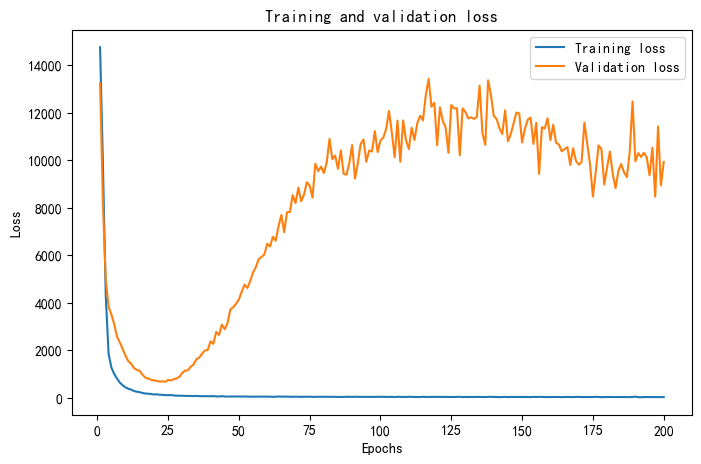

In [32]:
history_dict = history.history
loss_values = history_dict['loss']
mae=history_dict["mae"]
mse=history_dict["mse"]
val_loss = history_dict['val_loss']
val_mae = history_dict['val_mae']
val_mse = history_dict['val_mse']
epochs = range(1, len(loss_values) + 1)

plt.figure(figsize=(8,5))
plt.plot(range(1, len(loss_values) + 1), loss_values, label = 'Training loss')
plt.plot(range(1, len(val_loss) + 1), val_loss, label = 'Validation loss')
plt.title('Training and validation loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()


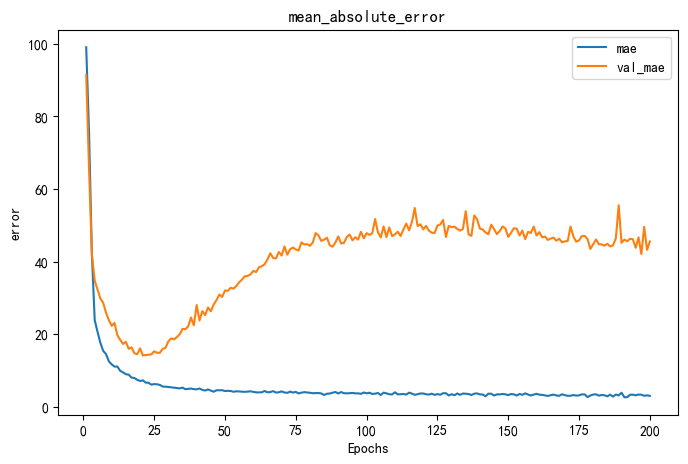

In [33]:
plt.figure(figsize=(8,5))
plt.plot(range(1, len(mae) + 1), mae, label = 'mae')
plt.plot(range(1, len(val_mae) + 1), val_mae, label = 'val_mae')
plt.title('mean_absolute_error')
plt.xlabel('Epochs')
plt.ylabel('error')
plt.legend()
plt.show()


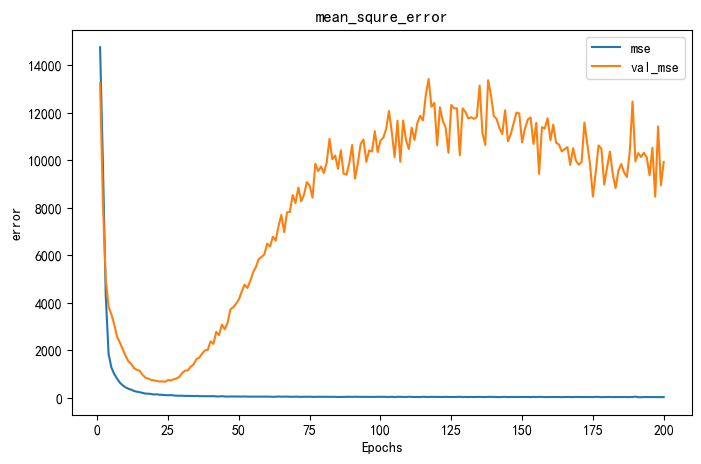

In [23]:
plt.figure(figsize=(8,5))
plt.plot(range(1, len(mse) + 1), mse, label = 'mse')
plt.plot(range(1, len(val_mse) + 1), val_mse, label = 'val_mse')
plt.title('mean_squre_error')
plt.xlabel('Epochs')
plt.ylabel('error')
plt.legend()
plt.show()


In [29]:
from math import sqrt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score  # Import R2 score function

# Assuming 'model_tf' is your trained TensorFlow model and 'test_x' and 'test_y' are your testing datasets
ypred = model_tf.predict(test_x)
mae = mean_absolute_error(test_y, ypred)
mse = mean_squared_error(test_y, ypred)
rmse = sqrt(mse)
r2 = r2_score(test_y, ypred)  # Calculate R2 score

print("MAE: %.2f" % mae)
print("MSE: %.2f" % mse)
print("RMSE: %.2f" % rmse)
print("R2 Score: %.2f" % r2)  # Print R2 score





28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 778us/step
MAE: 15.31
MSE: 1115.30
RMSE: 33.40
R2 Score: 0.81


In [26]:
test_y = np.array(y_test)


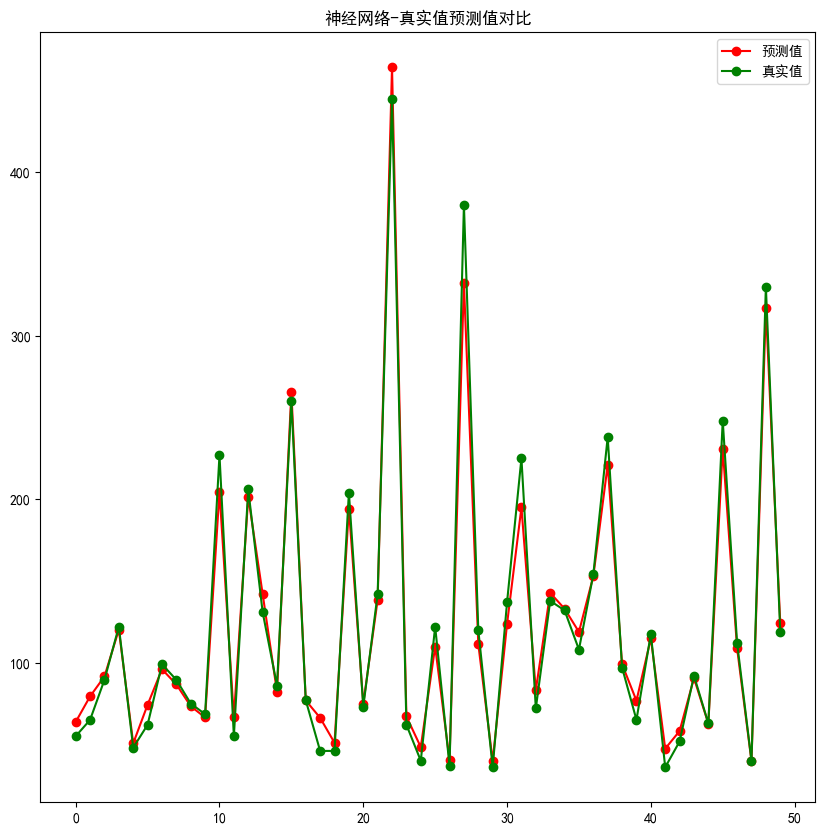

In [35]:
plt.figure(figsize=(10,10))
plt.title('神经网络-真实值预测值对比')
plt.plot(predict_y[:50], 'ro-', label='预测值')
plt.plot(test_y[:50], 'go-', label='真实值')
plt.legend()
plt.show()
